# Homework 3 – Time Series Classification (AReM)

Harsh Toshniwal

In [1]:
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif

warnings.filterwarnings('ignore')

## 1(a) Load the data

In [2]:
# Look at the raw file first
with open('AReM/bending1/dataset1.csv') as f:
    for i in range(8):
        print(f.readline(), end='')

# Task: bending1
# Frequency (Hz): 20
# Clock (millisecond): 250
# Duration (seconds): 120
# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,39.25,0.43,22.75,0.43,33.75,1.30
250,39.25,0.43,23.00,0.00,33.00,0.00
500,39.25,0.43,23.25,0.43,33.00,0.00


In [3]:
columns = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

df = pd.read_csv('AReM/bending1/dataset1.csv', comment='#', header=None, names=columns)
df.head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


In [4]:
df.shape

(480, 7)

## 1(b) Train / test split

Datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2, and 3 in every
other folder, are test data. Everything else is training data.

In [5]:
test_directory = ['AReM/bending1/dataset1.csv' , 'AReM/bending1/dataset2.csv' ,
                  'AReM/bending2/dataset1.csv' , 'AReM/bending2/dataset2.csv' ,
                  'AReM/cycling/dataset1.csv' , 'AReM/cycling/dataset2.csv' , 'AReM/cycling/dataset3.csv' ,
                  'AReM/lying/dataset1.csv' , 'AReM/lying/dataset2.csv' , 'AReM/lying/dataset3.csv' ,
                  'AReM/sitting/dataset1.csv' , 'AReM/sitting/dataset2.csv' , 'AReM/sitting/dataset3.csv' ,
                  'AReM/standing/dataset1.csv' , 'AReM/standing/dataset2.csv' , 'AReM/standing/dataset3.csv' ,
                  'AReM/walking/dataset1.csv' , 'AReM/walking/dataset2.csv' , 'AReM/walking/dataset3.csv']

In [6]:
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

train_directory = []
for activity in activities:
    files = glob.glob('AReM/' + activity + '/*.csv')
    files = [f.replace('\\', '/') for f in files]
    files = sorted(files, key=lambda f: int(f.split('dataset')[1].split('.')[0]))
    for f in files:
        if f not in test_directory:
            train_directory.append(f)

print(len(train_directory), 'train files')
print(len(test_directory), 'test files')

69 train files
19 test files


## Load all files

Some files need minor cleaning: `bending2/dataset4.csv` is separated by spaces
instead of commas, and `cycling/dataset9.csv` and `cycling/dataset14.csv` have
a trailing comma on each line. Splitting on commas or whitespace and keeping
only the first 7 columns handles both.

In [7]:
train_data = []
train_labels = []

for path in train_directory:
    df = pd.read_csv(path, comment='#', header=None, sep=r'[,\s]+', engine='python',
                     usecols=range(7), names=columns)
    train_data.append(df)
    train_labels.append(path.split('/')[1])

len(train_data)

69

In [8]:
test_data = []
test_labels = []

for path in test_directory:
    df = pd.read_csv(path, comment='#', header=None, sep=r'[,\s]+', engine='python',
                     usecols=range(7), names=columns)
    test_data.append(df)
    test_labels.append(path.split('/')[1])

len(test_data)

19

### Check the loaded files

In [9]:
pd.crosstab(pd.Series(train_labels + test_labels, name='activity'),
            pd.Series(['train'] * len(train_labels) + ['test'] * len(test_labels), name='split'),
            margins=True)

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


In [10]:
# Any file that isn't 480 x 7 or has missing values
for path, df in zip(train_directory + test_directory, train_data + test_data):
    if df.shape != (480, 7) or df.isna().sum().sum() > 0:
        print(path, df.shape, 'missing:', df.isna().sum().sum())

AReM/sitting/dataset8.csv (479, 7) missing: 0


`sitting/dataset8.csv` has 479 rows instead of 480. One missing reading won't
change the summary statistics, so it's left as is.

In [11]:
# bending2/dataset4 was space-separated, check it loaded correctly
train_data[train_directory.index('AReM/bending2/dataset4.csv')].head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,32.50,0.50,0.0,0.0,19.0,1.00
1,250,32.50,0.50,0.0,0.0,18.5,0.50
2,500,32.75,0.43,1.0,0.0,18.0,0.00
3,750,32.50,0.50,0.0,0.0,17.5,0.50
4,1000,32.50,0.50,7.5,0.5,17.5,0.87


## 1(c) Feature Extraction

### 1(c)i. Time-domain features used in time series classification

*Note: AI (Claude) was used to research and compile this list of commonly used time-domain features for time series classification.*

Time-domain features are computed directly from the raw values of the series (no Fourier/wavelet transform). The commonly used ones are:

**Central tendency**
- **Mean** – average signal level
- **Median** – middle value, less sensitive to spikes than the mean
- **Mode** – most frequent value

**Spread / variability**
- **Standard deviation** and **variance** – how much the signal fluctuates around its mean
- **Range** – max − min
- **Interquartile range (IQR)** – Q3 − Q1, a spread measure that's robust to outliers
- **Mean absolute deviation (MAD)** – average absolute distance from the mean
- **Coefficient of variation** – std / mean, spread relative to the signal level

**Order statistics**
- **Minimum** and **maximum**
- **First quartile (Q1)** and **third quartile (Q3)**, and other percentiles (e.g. 10th, 90th)

**Shape of the distribution**
- **Skewness** – asymmetry of the values around the mean
- **Kurtosis** – how heavy the tails are / how peaky the distribution is

**Energy / magnitude**
- **Root mean square (RMS)** – overall magnitude of the signal
- **Energy** – sum of squared values
- **Sum of absolute values / signal magnitude area**

**Temporal behaviour (order of the values matters)**
- **Zero crossings / mean crossings** – how often the signal crosses zero or its mean, a rough measure of how fast it oscillates
- **Autocorrelation** at different lags – how similar the signal is to a shifted copy of itself
- **Number of peaks** and **peak-to-peak amplitude**
- **Slope / trend** – e.g. the slope of a linear fit over time
- **Mean of first differences** (mean absolute change between consecutive values)
- **Entropy** (e.g. sample entropy) – how regular or unpredictable the signal is


### 1(c)ii. Extract min, max, mean, median, std, 1st and 3rd quartile

For every instance we compute these 7 features on each of the 6 time series, giving 6 x 7 = 42 features per instance. The features are used directly without normalizing.

In [12]:
# Try it on one series first
s = train_data[0]['avg_rss12']
print('min:', s.min())
print('max:', s.max())
print('mean:', s.mean())
print('median:', s.median())
print('std:', s.std())
print('1st quart:', s.quantile(0.25))
print('3rd quart:', s.quantile(0.75))

min: 35.0
max: 47.4
mean: 43.9545
median: 44.33
std: 1.5588350663530308
1st quart: 43.0
3rd quart: 45.0


In [13]:
# Column names: min1, max1, ..., 3rd_quart6 (1-6 = the 6 time series in order)
series = columns[1:]

feature_names = []
for i in range(1, 7):
    feature_names += ['min' + str(i), 'max' + str(i), 'mean' + str(i), 'median' + str(i),
                      'std' + str(i), '1st_quart' + str(i), '3rd_quart' + str(i)]

len(feature_names)

42

In [14]:
all_data = train_data + test_data
all_labels = train_labels + test_labels

rows = []
for df in all_data:
    row = []
    for s in series:
        row += [df[s].min(), df[s].max(), df[s].mean(), df[s].median(),
                df[s].std(), df[s].quantile(0.25), df[s].quantile(0.75)]
    rows.append(row)

features = pd.DataFrame(rows, columns=feature_names)
features.index = range(1, len(features) + 1)
features.index.name = 'Instance'
features

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
2,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
3,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
4,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,0.378083,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
5,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,0.413125,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,0.506583,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
85,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,0.486167,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
86,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,3.995729,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425


In [15]:
print(features.shape)

# Keep the activity and train/test split alongside the features for later parts
features_labeled = features.copy()
features_labeled['activity'] = all_labels
features_labeled['split'] = ['train'] * len(train_data) + ['test'] * len(test_data)
features_labeled.head()

(88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,split
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,train
2,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,train
3,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,train
4,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,train
5,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,train


### 1(c)iii. Standard deviation of each feature and 90% bootstrap confidence interval

First the standard deviation of each of the 42 features across the 88 instances. Then for the bootstrap, we resample the 88 instances with replacement 1000 times, recompute the standard deviation of each feature every time, and take the 5th and 95th percentiles of those 1000 values as the 90% confidence interval.

In [16]:
feature_std = features.std()
feature_std

min1          9.569975
max1          4.394362
mean1         5.335718
median1       5.440054
std1          1.772153
1st_quart1    6.153590
3rd_quart1    5.138925
min2          0.000000
max2          5.062729
mean2         1.574164
median2       1.412244
std2          0.884105
1st_quart2    0.946386
3rd_quart2    2.125266
min3          2.956462
max3          4.875137
mean3         4.008380
median3       4.036396
std3          0.946710
1st_quart3    4.220658
3rd_quart3    4.171628
min4          0.000000
max4          2.183625
mean4         1.166114
median4       1.145586
std4          0.458242
1st_quart4    0.843620
3rd_quart4    1.552504
min5          6.124001
max5          5.741238
mean5         5.675593
median5       5.813782
std5          1.024898
1st_quart5    6.096465
3rd_quart5    5.531720
min6          0.045838
max6          2.518921
mean6         1.154812
median6       1.086474
std6          0.517617
1st_quart6    0.758584
3rd_quart6    1.523599
dtype: float64

In [17]:
# Bootstrap: resample instances with replacement and recompute the std each time
np.random.seed(42)
n_boot = 1000

boot_stds = []
for b in range(n_boot):
    sample = features.sample(n=len(features), replace=True)
    boot_stds.append(sample.std())

boot_stds = pd.DataFrame(boot_stds)
boot_stds.shape

(1000, 42)

In [18]:
ci_table = pd.DataFrame({'std': feature_std,
                         'CI lower (5%)': boot_stds.quantile(0.05),
                         'CI upper (95%)': boot_stds.quantile(0.95)})
ci_table

,std,CI lower (5%),CI upper (95%)
min1,9.569975,8.238436,10.736652
max1,4.394362,3.362410,5.352420
mean1,5.335718,4.695874,5.851096
median1,5.440054,4.793015,5.990190
std1,1.772153,1.569653,1.948218
1st_quart1,6.153590,5.565222,6.623545
3rd_quart1,5.138925,4.289877,5.845192
min2,0.000000,0.000000,0.000000
max2,5.062729,4.636494,5.416213
mean2,1.574164,1.406871,1.704059


The features from the `avg_rss` series (1, 3, 5) vary much more across instances than the ones from the `var_rss` series (2, 4, 6), which is expected since the averages are on a larger scale. `min2` and `min4` are 0 in every instance, so their std and CI are exactly 0 and they carry no information for classification.

### 1(c)iv. Selecting the three most important features

A good feature should take clearly different values for different activities. To judge this we use only the training instances and:
1. look at boxplots of each feature grouped by activity,
2. compute the ANOVA F-score of each feature (between-activity variance / within-activity variance; higher means better separation),
3. check how correlated the feature types are, so we don't pick three that carry the same information.

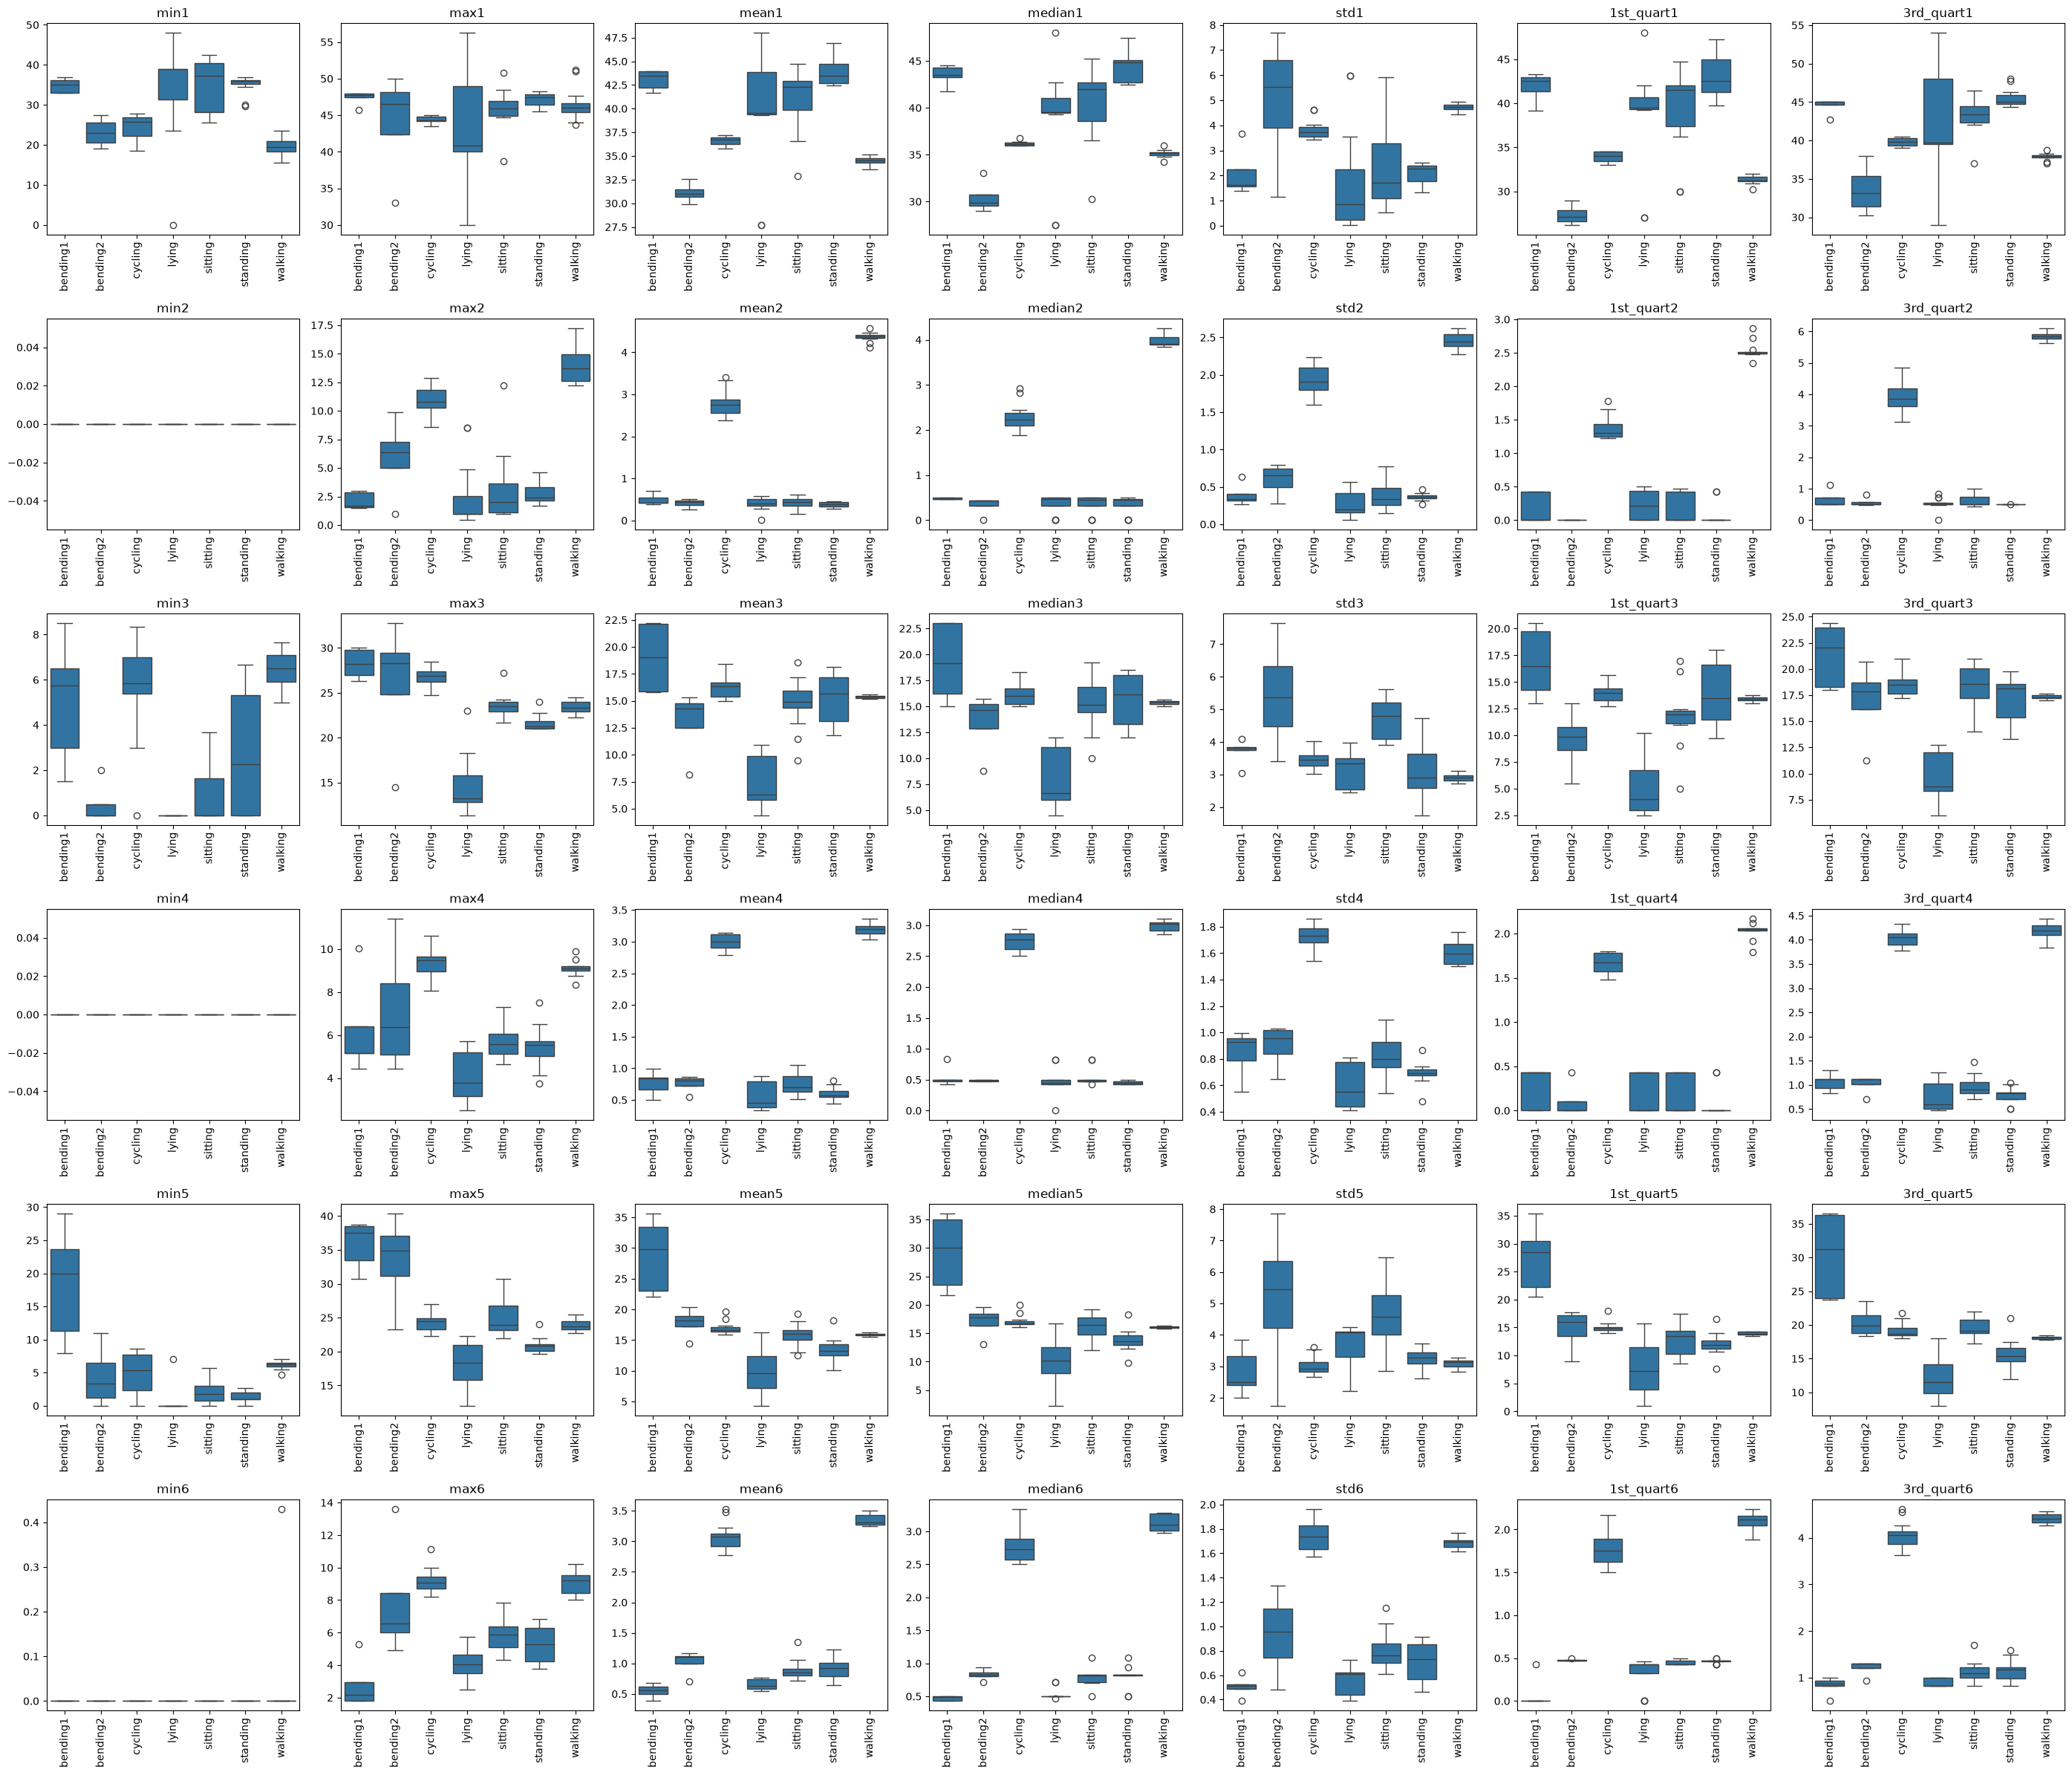

In [19]:
train_features = features_labeled[features_labeled['split'] == 'train']
feature_types = ['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']

# Rows = the 6 time series, columns = the 7 feature types
fig, axes = plt.subplots(6, 7, figsize=(28, 24))
for i in range(6):
    for j in range(7):
        col = feature_types[j] + str(i + 1)
        sns.boxplot(data=train_features, x='activity', y=col, ax=axes[i, j])
        axes[i, j].set_title(col)
        axes[i, j].set_xlabel('')
        axes[i, j].set_ylabel('')
        axes[i, j].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [20]:
# ANOVA F-score of every feature against the activity label
F, p = f_classif(train_features[feature_names], train_features['activity'])
F = pd.Series(F, index=feature_names).fillna(0)   # min2 and min4 are constant -> F = 0

# Put it in a table: rows = time series, columns = feature type
f_table = pd.DataFrame(index=range(1, 7), columns=feature_types, dtype=float)
for i in range(1, 7):
    for t in feature_types:
        f_table.loc[i, t] = F[t + str(i)]
f_table.index.name = 'time series'
f_table.round(1)

,min,max,mean,median,std,1st_quart,3rd_quart
time series,,,,,,,
1,11.0,1.5,15.9,17.5,9.1,21.4,8.5
2,0.0,47.7,900.2,477.0,360.9,265.5,807.0
3,22.7,31.7,26.4,19.4,15.2,21.2,28.1
4,0.0,29.3,651.8,800.8,128.6,244.8,561.9
5,24.1,37.0,33.4,28.6,7.8,25.5,32.2
6,0.8,33.0,581.5,563.1,133.4,346.3,664.8


In [21]:
# Average F-score of each feature type over the 6 time series
f_table.mean().sort_values(ascending=False).round(1)

mean         368.2
3rd_quart    350.4
median       317.7
1st_quart    154.1
std          109.2
max           30.0
min            9.8
dtype: float64

In [22]:
# Correlation between feature types, averaged over the 6 time series
# (min2 and min4 are constant so their correlations are NaN and get skipped)
corrs = []
for i in range(1, 7):
    cols = [t + str(i) for t in feature_types]
    c = train_features[cols].corr()
    c.index = feature_types
    c.columns = feature_types
    corrs.append(c)

avg_corr = pd.concat(corrs).groupby(level=0).mean().loc[feature_types]
avg_corr.round(2)

,min,max,mean,median,std,1st_quart,3rd_quart
min,1.00,0.36,0.59,0.57,-0.32,0.60,0.52
max,0.36,1.00,0.79,0.75,0.63,0.71,0.82
mean,0.59,0.79,1.00,0.99,0.38,0.98,0.98
median,0.57,0.75,0.99,1.00,0.36,0.98,0.96
std,-0.32,0.63,0.38,0.36,1.00,0.28,0.50
1st_quart,0.60,0.71,0.98,0.98,0.28,1.00,0.93
3rd_quart,0.52,0.82,0.98,0.96,0.50,0.93,1.00


**Chosen features: mean, standard deviation, and maximum.**

- **Mean** has the highest average F-score. In the boxplots, `mean2`, `mean4` and `mean6` clearly separate cycling and walking from the rest, and `mean1`/`mean5` separate bending1, bending2 and lying.
- **Median, 1st quartile and 3rd quartile** also score high, but they are 0.93–0.99 correlated with the mean, so adding them would mostly repeat the same information.
- **Standard deviation** has the highest F-score among the features that aren't redundant with the mean (only ~0.38 correlation), so it adds new information about how much the signal fluctuates (e.g. `std1`, `std3`, `std5` single out bending2).
- **Maximum** captures the peaks of the signal (e.g. `max2`/`max6` separate walking, cycling and bending2) and is less redundant with the mean than the quartiles are.
- **Minimum** is the weakest: `min2` and `min4` are 0 for every instance and the other mins overlap a lot between activities.